# PHÂN TÍCH DỮ LIỆU TITANIC

## Giai đoạn 1 — Thu thập và đánh giá dữ liệu

In [27]:
# Cài thư viện 
%pip -q install -U xgboost

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cài dữ liệu
url_du_lieu = "https://raw.githubusercontent.com/hnhun2306b5tneu-crypto/Titanic/main/data/train.csv"
du_lieu_goc = pd.read_csv(url_du_lieu)
print("Kích thước dữ liệu:", du_lieu_goc.shape)
display(du_lieu_goc.head())

Note: you may need to restart the kernel to use updated packages.
Kích thước dữ liệu: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 2. Kiểm tra cấu trúc, giá trị thiếu và dữ liệu trùng

In [7]:
# Xem số dòng, cột và kiểu dữ liệu
print("Số dòng và cột:", du_lieu_goc.shape)
du_lieu_goc.info()
display(du_lieu_goc.describe(include="all").T)

Số dòng và cột: (891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


In [8]:
# Tính số lượng và tỷ lệ dữ liệu thiếu
bang_thieu = pd.DataFrame({
    "Số giá trị thiếu": du_lieu_goc.isna().sum(),
    "Tỷ lệ thiếu (%)": (du_lieu_goc.isna().mean() * 100).round(2)
})
print("Số dòng trùng hoàn toàn:", du_lieu_goc.duplicated().sum())
print("Số mã hành khách trùng:", du_lieu_goc["PassengerId"].duplicated().sum())
display(bang_thieu.sort_values("Tỷ lệ thiếu (%)", ascending=False))

Số dòng trùng hoàn toàn: 0
Số mã hành khách trùng: 0


,Số giá trị thiếu,Tỷ lệ thiếu (%)
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


## Giai đoạn 2 — Làm sạch và chuẩn bị dữ liệu

In [9]:
# Tạo bản sao và làm sạch các trường cần phân tích
du_lieu = du_lieu_goc.copy()
du_lieu = du_lieu.drop_duplicates(subset="PassengerId")
du_lieu["Embarked"] = du_lieu["Embarked"].fillna(du_lieu["Embarked"].mode()[0])

# Tạo nhóm tuổi và số người thân đi cùng
du_lieu["Nhom_tuoi"] = pd.cut(
    du_lieu["Age"], bins=[0, 12, 18, 35, 60, 100],
    labels=["Trẻ em", "13–18", "19–35", "36–60", "Trên 60"],
    include_lowest=True
)
du_lieu["So_nguoi_than"] = du_lieu["SibSp"] + du_lieu["Parch"]
du_lieu["Di_mot_minh"] = du_lieu["So_nguoi_than"].eq(0).map({True:"Một mình",False:"Có người thân"})
du_lieu["Trang_thai"] = du_lieu["Survived"].map({0:"Không sống sót",1:"Sống sót"})
print("Số hành khách sau làm sạch:",len(du_lieu))
display(du_lieu[["Survived","Sex","Pclass","Age","Nhom_tuoi","So_nguoi_than","Embarked"]].head())

Số hành khách sau làm sạch: 891


,Survived,Sex,Pclass,Age,Nhom_tuoi,So_nguoi_than,Embarked
0,0,male,3,22.0,19–35,1,S
1,1,female,1,38.0,36–60,1,C
2,1,female,3,26.0,19–35,0,S
3,1,female,1,35.0,19–35,1,S
4,0,male,3,35.0,19–35,0,S


In [10]:
# Kiểm tra giá vé bằng tứ phân vị IQR (chỉ nhận diện, không xóa)
q1 = du_lieu["Fare"].quantile(0.25)
q3 = du_lieu["Fare"].quantile(0.75)
iqr = q3 - q1
gioi_han_tren = q3 + 1.5 * iqr
so_ve_cao = (du_lieu["Fare"] > gioi_han_tren).sum()
print("Ngưỡng vé cao theo IQR:",round(gioi_han_tren,2))
print("Số vé vượt ngưỡng:",so_ve_cao)

Ngưỡng vé cao theo IQR: 65.63
Số vé vượt ngưỡng: 116


**Giải Trình:**

1.   Age: Giữ giá trị thiếu để tránh làm sai lệch phân bố tuổi.

2.  Embarked: Điền Mode vì là biến phân loại.

3.  Cabin: Không phân tích vì thiếu khoảng 77% dữ liệu.

4.  Trùng lặp: Kiểm tra và loại bỏ để tránh sai lệch kết quả.

5.  Outliers: Dùng IQR để phát hiện, không xóa vì giá vé cao có thể hợp lệ.
   



## Giai đoạn 3 — Thống kê, trực quan hóa và kiểm định


### 1. Tỉ lệ sống sót

Tỷ lệ sống sót : 38.4 %


,Số hành khách
Trang_thai,
Không sống sót,549
Sống sót,342


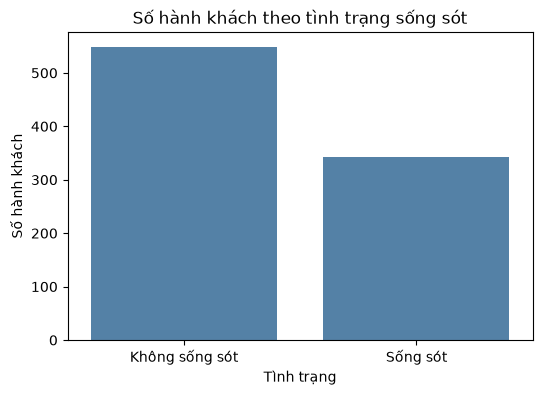

In [11]:
# Đếm người sống sót và tính tỷ lệ chung
bang_song_sot = du_lieu["Trang_thai"].value_counts()
ty_le_chung = du_lieu["Survived"].mean() * 100
print("Tỷ lệ sống sót :",round(ty_le_chung,1),"%")
display(bang_song_sot.to_frame("Số hành khách"))
plt.figure(figsize=(6,4))
sns.countplot(data=du_lieu, color="steelblue", x="Trang_thai", order=["Không sống sót","Sống sót"])
plt.title("Số hành khách theo tình trạng sống sót")
plt.xlabel("Tình trạng")
plt.ylabel("Số hành khách")
plt.show()

### 2. Sự liên hệ giữa giới tính và tỉ lệ sống sót

,count,Tỷ lệ sống (%)
Sex,,
female,314,74.2
male,577,18.9


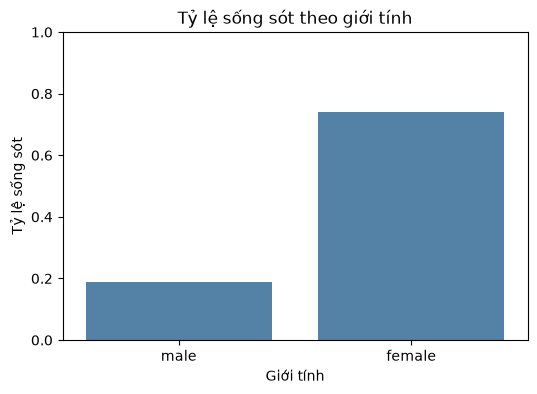

In [12]:
# So sánh số lượng và tỷ lệ sống sót theo giới tính
bang_gioi_tinh = du_lieu.groupby("Sex")["Survived"].agg(["count","mean"])
bang_gioi_tinh["Tỷ lệ sống (%)"] = (bang_gioi_tinh["mean"]*100).round(1)
display(bang_gioi_tinh[["count","Tỷ lệ sống (%)"]])
plt.figure(figsize=(6,4))
sns.barplot(color="steelblue",data=du_lieu, x="Sex", y="Survived", errorbar=None)
plt.title("Tỷ lệ sống sót theo giới tính")
plt.xlabel("Giới tính")
plt.ylabel("Tỷ lệ sống sót")
plt.ylim(0,1)
plt.show()

**Nhận xét:** Nữ có tỉ lệ sống sót vượt trội so với Nam

### 3. Sự liên hệ giữa hạng vé và tỉ lệ sống sót

,count,Tỷ lệ sống (%)
Pclass,,
1,216,63.0
2,184,47.3
3,491,24.2


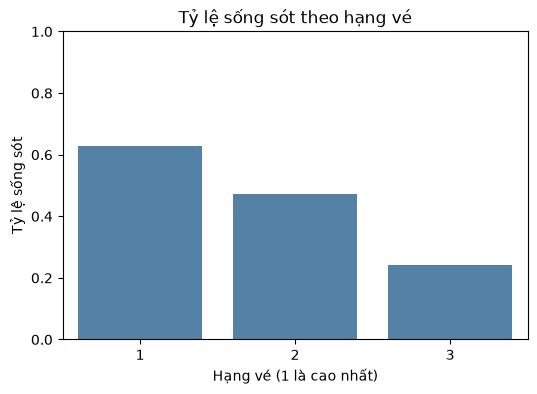

In [13]:
# So sánh tỷ lệ sống sót theo hạng vé
bang_hang_ve = du_lieu.groupby("Pclass")["Survived"].agg(["count","mean"])
bang_hang_ve["Tỷ lệ sống (%)"] = (bang_hang_ve["mean"]*100).round(1)
display(bang_hang_ve[["count","Tỷ lệ sống (%)"]])
plt.figure(figsize=(6,4))
sns.barplot(color="steelblue",data=du_lieu, x="Pclass",y="Survived",errorbar=None)
plt.title("Tỷ lệ sống sót theo hạng vé")
plt.xlabel("Hạng vé (1 là cao nhất)")
plt.ylabel("Tỷ lệ sống sót")
plt.ylim(0,1)
plt.show()

**Nhận xét:** Hạng vé 1 có tỉ lệ sống sót cao hơn hạng vé 2, hạng vé 2 cũng có tỉ lệ sống sót cao hơn hạng vé 3.

### 4. Mối liên hệ giữa hạng vé và sống sót có khác nhau theo giới tính?

Pclass,1,2,3
Sex,,,
female,96.8,92.1,50.0
male,36.9,15.7,13.5


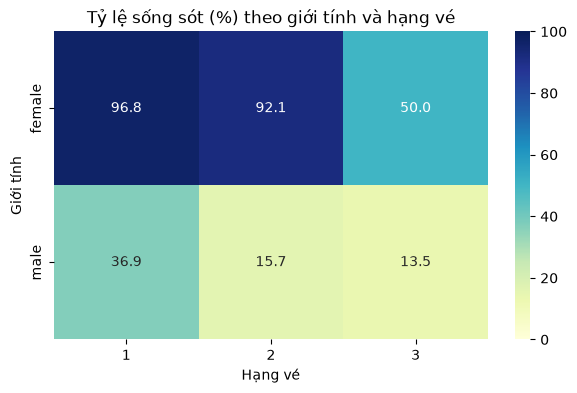

In [14]:
# Tạo bảng tỷ lệ sống theo giới tính và hạng vé
bang_gioi_hang = du_lieu.pivot_table(values="Survived",index="Sex",columns="Pclass",aggfunc="mean")
display((bang_gioi_hang*100).round(1))
plt.figure(figsize=(7,4))
sns.heatmap(bang_gioi_hang*100,annot=True,fmt=".1f",cmap="YlGnBu",vmin=0,vmax=100)
plt.title("Tỷ lệ sống sót (%) theo giới tính và hạng vé")
plt.xlabel("Hạng vé")
plt.ylabel("Giới tính")
plt.show()

**Nhận xét:**

1.   Giới tính: Nữ có tỷ lệ sống sót cao hơn nam ở cả 3 hạng vé.

2.  Hạng vé: Hành khách hạng 1 có tỷ lệ sống sót cao hơn hạng 2 và hạng 3 ở cả hai giới.

3.  Nữ hạng 1 và 2: Có tỷ lệ sống sót rất cao, lần lượt là 96,8% và 92,1%.

4.  Nam hạng 3: Có tỷ lệ sống sót thấp nhất, chỉ 13,5%.




### 5. Sự liên hệ giữa tuổi và tỉ lệ sống sót

,count,Tỷ lệ sống (%)
Nhom_tuoi,,
Trẻ em,69,58.0
13–18,70,42.9
19–35,358,38.3
36–60,195,40.0
Trên 60,22,22.7


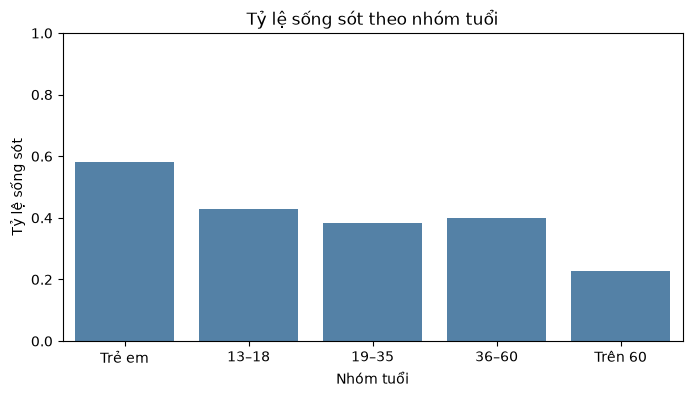

Số dòng thiếu tuổi không dùng trong câu này: 177


In [15]:
# Bỏ các dòng thiếu tuổi trong riêng phần phân tích tuổi
du_lieu_co_tuoi = du_lieu.dropna(subset=["Age"]).copy()
bang_tuoi = du_lieu_co_tuoi.groupby("Nhom_tuoi",observed=True)["Survived"].agg(["count","mean"])
bang_tuoi["Tỷ lệ sống (%)"] = (bang_tuoi["mean"]*100).round(1)
display(bang_tuoi[["count","Tỷ lệ sống (%)"]])
plt.figure(figsize=(8,4))
sns.barplot(color="steelblue",data=du_lieu_co_tuoi,x="Nhom_tuoi",y="Survived",errorbar=None)
plt.title("Tỷ lệ sống sót theo nhóm tuổi")
plt.xlabel("Nhóm tuổi")
plt.ylabel("Tỷ lệ sống sót")
plt.ylim(0,1)
plt.show()
print("Số dòng thiếu tuổi không dùng trong câu này:",du_lieu["Age"].isna().sum())

**Nhận xét:** Tuổi càng trẻ thường có tỷ lệ sống sót cao hơn, đặc biệt là trẻ em. Tuy nhiên có 1 số dữ liệu thiếu tuổi nên tỷ lệ thực tế có thể khác.

### 6. So sánh tỷ lệ sống sót khi đi một mình và đi cùng người thân

,count,Tỷ lệ sống (%)
Di_mot_minh,,
Có người thân,354,50.6
Một mình,537,30.4


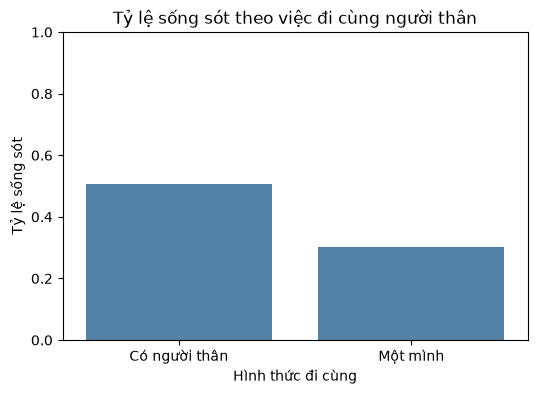

In [16]:
# So sánh hành khách đi một mình với đi cùng người thân
bang_di_cung = du_lieu.groupby("Di_mot_minh")["Survived"].agg(["count","mean"])
bang_di_cung["Tỷ lệ sống (%)"] = (bang_di_cung["mean"]*100).round(1)
display(bang_di_cung[["count","Tỷ lệ sống (%)"]])
plt.figure(figsize=(6,4))
sns.barplot(color="steelblue",data=du_lieu,x="Di_mot_minh",y="Survived",errorbar=None)
plt.title("Tỷ lệ sống sót theo việc đi cùng người thân")
plt.xlabel("Hình thức đi cùng")
plt.ylabel("Tỷ lệ sống sót")
plt.ylim(0,1)
plt.show()

###  7. Kích thước nhóm và tỉ lệ sống sốt

,count,Tỷ lệ sống (%)
Nhom_gia_dinh,,
0 người,537,30.4
1–2 người,263,56.3
3–5 người,66,40.9
Trên 5 người,25,16.0


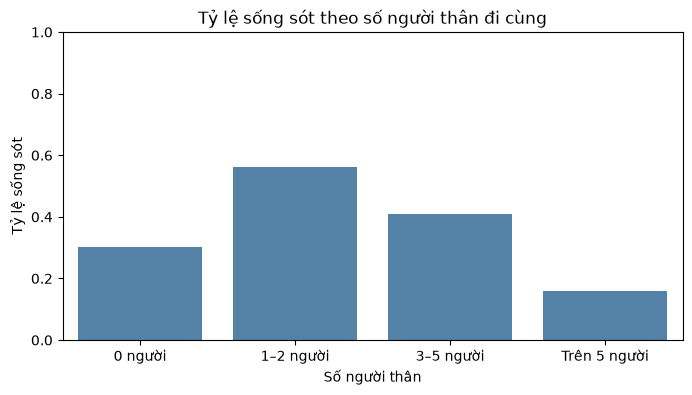

In [17]:
# Nhóm số người thân để so sánh dễ hơn
du_lieu["Nhom_gia_dinh"] = pd.cut(
    du_lieu["So_nguoi_than"],bins=[-1,0,2,5,20],
    labels=["0 người", "1–2 người", "3–5 người", "Trên 5 người"]
)
bang_gia_dinh = du_lieu.groupby("Nhom_gia_dinh",observed=True)["Survived"].agg(["count","mean"])
bang_gia_dinh["Tỷ lệ sống (%)"] = (bang_gia_dinh["mean"]*100).round(1)
display(bang_gia_dinh[["count","Tỷ lệ sống (%)"]])
plt.figure(figsize=(8,4))
sns.barplot(color="steelblue",data=du_lieu,x="Nhom_gia_dinh",y="Survived",errorbar=None)
plt.title("Tỷ lệ sống sót theo số người thân đi cùng")
plt.xlabel("Số người thân")
plt.ylabel("Tỷ lệ sống sót")
plt.ylim(0,1)
plt.show()

**Nhận xét:** Tỷ lệ sống sót khi có 1-2 người thân đi cùng cao nhưng do số lượng cũng khá cao nên chưa thể đưa ra kết luận gì ở đây.

### 8. Giới tính và tình trạng sống sót có liên quan không?
Sử dụng kiểm định Chi-square (5%).

In [18]:
# Tạo bảng chéo và kiểm định Chi-square
from scipy.stats import chi2_contingency
bang_kiem_dinh = pd.crosstab(du_lieu["Sex"],du_lieu["Survived"])
chi_binh_phuong, gia_tri_p, bac_tu_do, bang_ky_vong = chi2_contingency(bang_kiem_dinh)
display(bang_kiem_dinh)
print("Giá trị p:",format(gia_tri_p,".6g"))
if gia_tri_p < 0.05:
    print("Có bằng chứng về mối liên hệ giữa giới tính và sống sót (p < 0,05).")
else:
    print("Chưa đủ bằng chứng về mối liên hệ (p >= 0,05).")

Survived,0,1
Sex,,
female,81,233
male,468,109


Giá trị p: 1.19736e-58
Có bằng chứng về mối liên hệ giữa giới tính và sống sót (p < 0,05).


**Nhận xét:** Có sự bằng chứng thống kê về sự liên quan giữa giới tính và tỉ lệ sống sót

### 9. Giá vé và tỷ lệ sống sót: phân tích trong từng hạng vé

**Cách làm:** Chia giá vé thành các nhóm *trong từng hạng* bằng phân vị, rồi đối chiếu tỷ lệ sống sót. Điều này giảm nhầm lẫn do hành khách hạng cao thường có vé đắt hơn. Kết quả là **mối liên hệ**, không phải nguyên nhân.

count  Tỷ lệ sống (%)
Pclass Nhom_gia_trong_hang                       
1      Thấp                    72            44.4
       Trung bình              72            66.7
       Cao                     72            77.8
2      Thấp                    62            33.9
       Trung bình              61            50.8
       Cao                     61            57.4
3      Thấp                   164            23.8
       Trung bình             163            17.2
       Cao                    164            31.7

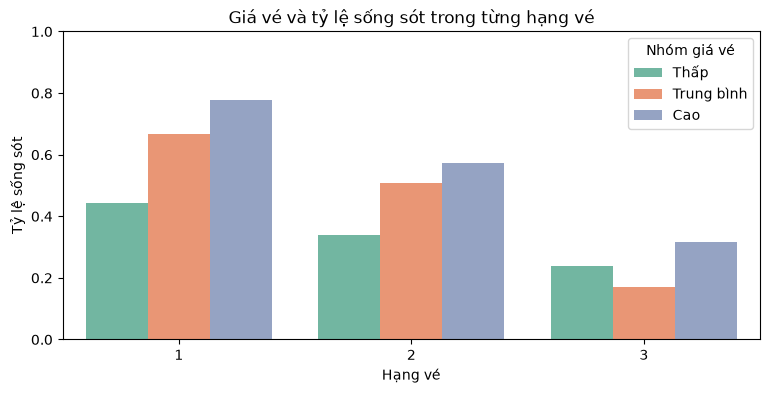

In [19]:
# Tạo nhóm vé thấp / giữa / cao riêng trong từng hạng vé
phan_tich_ve = du_lieu[["Pclass", "Fare", "Survived"]].copy()
phan_tich_ve["Nhom_gia_trong_hang"] = phan_tich_ve.groupby("Pclass")["Fare"].transform(
    lambda cot: pd.qcut(cot.rank(method="first"), q=3, labels=["Thấp", "Trung bình", "Cao"])
)
bang_ve = phan_tich_ve.groupby(["Pclass", "Nhom_gia_trong_hang"], observed=True)["Survived"].agg(["count", "mean"])
bang_ve["Tỷ lệ sống (%)"] = (100 * bang_ve["mean"]).round(1)
display(bang_ve[["count", "Tỷ lệ sống (%)"]])
plt.figure(figsize=(9, 4))
sns.barplot(data=phan_tich_ve, x="Pclass", y="Survived", hue="Nhom_gia_trong_hang", palette="Set2", errorbar=None)
plt.title("Giá vé và tỷ lệ sống sót trong từng hạng vé")
plt.xlabel("Hạng vé")
plt.ylabel("Tỷ lệ sống sót")
plt.ylim(0, 1)
plt.legend(title="Nhóm giá vé")
plt.show()

### 10. Đồng thời xem xét tuổi, giới tính và hạng vé

**Cách làm:** Tổng hợp tỷ lệ sống sót theo ba chiều. Chỉ tập trung nhóm đủ quan sát; ô ít người có thể biến động mạnh.

,Sex,Pclass,Tuoi_3_nhom,count,Tỷ lệ sống (%)
0,female,1,Trẻ em ≤12,1,0.0
1,female,1,13–50,71,97.2
2,female,1,Trên 50,13,100.0
3,female,2,Trẻ em ≤12,8,100.0
4,female,2,13–50,63,92.1
5,female,2,Trên 50,3,66.7
6,female,3,Trẻ em ≤12,23,47.8
7,female,3,13–50,78,44.9
8,female,3,Trên 50,1,100.0
9,male,1,Trẻ em ≤12,3,100.0


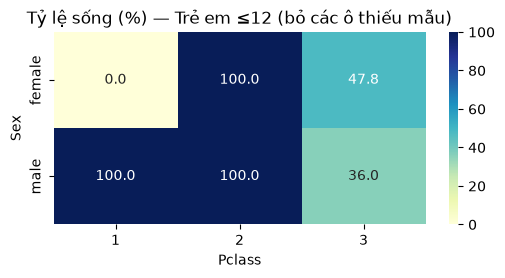

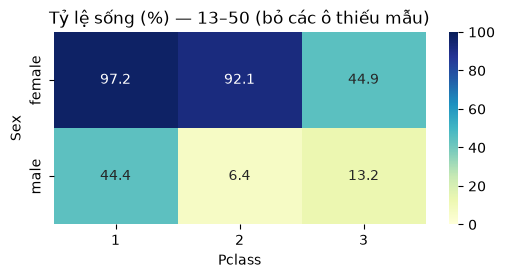

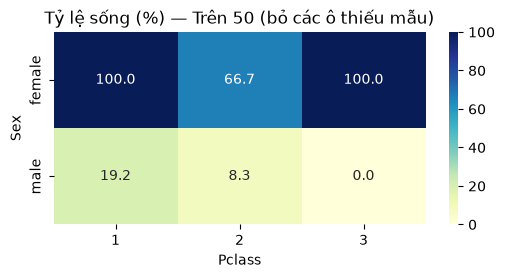

Số hành khách thiếu tuổi không góp mặt: 177


In [20]:
# Nhóm tuổi đơn giản để hạn chế các ô quá ít mẫu
du_lieu_nhom_tuoi = du_lieu.copy()
du_lieu_nhom_tuoi["Tuoi_3_nhom"] = pd.cut(
    du_lieu_nhom_tuoi["Age"], [-0.1, 12, 50, 100],
    labels=["Trẻ em ≤12", "13–50", "Trên 50"]
)
bang_ba_chieu = du_lieu_nhom_tuoi.groupby(
    ["Sex", "Pclass", "Tuoi_3_nhom"], observed=True
)["Survived"].agg(["count", "mean"]).reset_index()
bang_ba_chieu["Tỷ lệ sống (%)"] = (bang_ba_chieu["mean"] * 100).round(1)
display(bang_ba_chieu[["Sex", "Pclass", "Tuoi_3_nhom", "count", "Tỷ lệ sống (%)"]])

# Heatmap số liệu theo giới tính/hạng, tách thành từng nhóm tuổi
for nhom_tuoi in du_lieu_nhom_tuoi["Tuoi_3_nhom"].cat.categories:
    du_lieu_nhom = bang_ba_chieu[bang_ba_chieu["Tuoi_3_nhom"] == nhom_tuoi]
    bang_hien_thi = du_lieu_nhom.pivot(index="Sex", columns="Pclass", values="Tỷ lệ sống (%)")
    plt.figure(figsize=(6, 2.5))
    sns.heatmap(bang_hien_thi, annot=True, fmt=".1f", cmap="YlGnBu", vmin=0, vmax=100)
    plt.title(f"Tỷ lệ sống (%) — {nhom_tuoi} (bỏ các ô thiếu mẫu)")
    plt.show()
print("Số hành khách thiếu tuổi không góp mặt:", du_lieu_nhom_tuoi["Age"].isna().sum())

### 11. Danh xưng trong tên hành khách

**Cách làm:** Trích danh xưng (Mr, Mrs, Miss, Master...) từ `Name` rồi thống kê số lượng và tỷ lệ sống. Phân nhóm hiếm để tránh quá nhiều nhãn nhỏ.

,count,Tỷ lệ sống (%)
Danh_xung,,
Mr,517,15.7
Miss,182,69.8
Mrs,125,79.2
Master,40,57.5
Khác,27,44.4


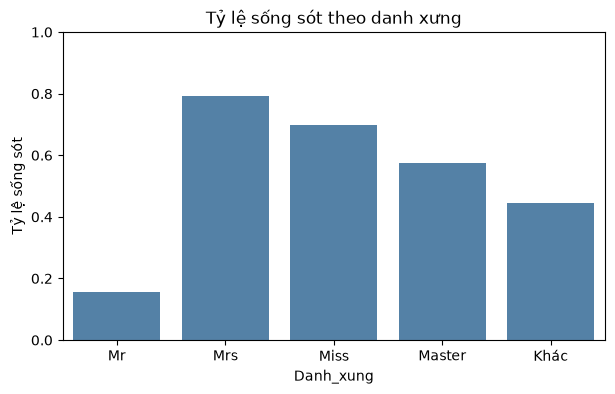

In [21]:
# Danh xưng nằm giữa dấu phẩy và dấu chấm trong tên
phan_tich_ten = du_lieu[["Name", "Survived"]].copy()
phan_tich_ten["Danh_xung"] = phan_tich_ten["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()
phan_tich_ten["Danh_xung"] = phan_tich_ten["Danh_xung"].where(
    phan_tich_ten["Danh_xung"].isin(["Mr", "Mrs", "Miss", "Master"]), "Khác"
)
bang_danh_xung = phan_tich_ten.groupby("Danh_xung")["Survived"].agg(["count", "mean"])
bang_danh_xung["Tỷ lệ sống (%)"] = (bang_danh_xung["mean"] * 100).round(1)
display(bang_danh_xung[["count", "Tỷ lệ sống (%)"]].sort_values("count", ascending=False))
plt.figure(figsize=(7, 4))
sns.barplot(data=phan_tich_ten, x="Danh_xung", y="Survived", color="steelblue", errorbar=None)
plt.ylim(0, 1)
plt.title("Tỷ lệ sống sót theo danh xưng")
plt.ylabel("Tỷ lệ sống sót")
plt.show()

### 12. Cảng lên tàu: sự khác biệt có ý nghĩa thống kê không?

**Cách làm:** Tạo bảng chéo cảng × sống sót, kiểm định Chi-square ở mức 5% và tính **Cramér's V** để đánh giá độ mạnh liên hệ. Đây vẫn chỉ là kiểm định liên hệ hai biến.

In [22]:
from scipy.stats import chi2_contingency

bang_cang = pd.crosstab(du_lieu["Embarked"], du_lieu["Survived"])
chi2_cang, p_cang, _, tan_suat_ky_vong = chi2_contingency(bang_cang)
cramers_v_cang = np.sqrt(chi2_cang / (bang_cang.to_numpy().sum() * min(bang_cang.shape[0]-1, bang_cang.shape[1]-1)))
display(bang_cang)
print(f"Chi-square p-value: {p_cang:.6g} | Cramér's V: {cramers_v_cang:.3f}")
print("Tần suất kỳ vọng tối thiểu:", round(tan_suat_ky_vong.min(), 2))
print("Kết luận:", "Có bằng chứng về liên hệ" if p_cang < 0.05 else "Chưa đủ bằng chứng về liên hệ")

ty_le_cang = (du_lieu.groupby("Embarked")["Survived"].mean() * 100).round(1)
display(ty_le_cang.rename("Tỷ lệ sống (%)").to_frame())

Survived,0,1
Embarked,,
C,75,93
Q,47,30
S,427,219


Chi-square p-value: 2.30086e-06 | Cramér's V: 0.171
Tần suất kỳ vọng tối thiểu: 29.56
Kết luận: Có bằng chứng về liên hệ


,Tỷ lệ sống (%)
Embarked,
C,55.4
Q,39.0
S,33.9


### 13. Khoảng tin cậy 95% cho tỷ lệ sống sót

**Cách làm:** Dùng khoảng tin cậy Wilson cho từng nhóm. Một tỷ lệ ước lượng từ nhóm ít người thường có khoảng tin cậy rộng hơn.

,Sex,Pclass,count,sum,Tỷ lệ (%),CI dưới (%),CI trên (%)
0,female,1,94,91,96.8,91.0,98.9
1,female,2,76,70,92.1,83.8,96.3
2,female,3,144,72,50.0,41.9,58.1
3,male,1,122,45,36.9,28.8,45.7
4,male,2,108,17,15.7,10.1,23.8
5,male,3,347,47,13.5,10.3,17.5


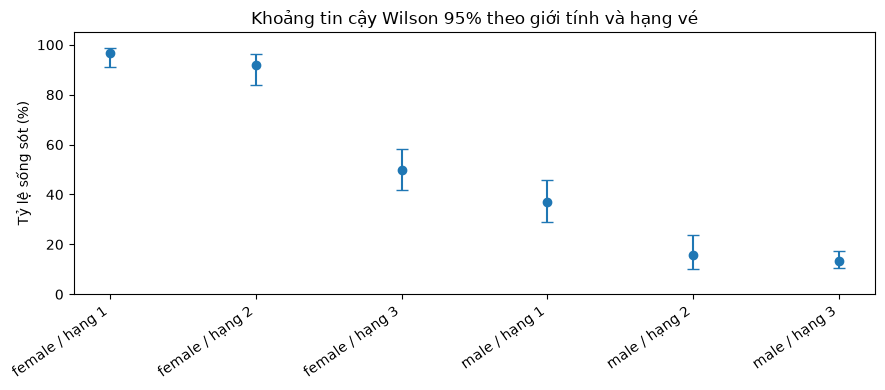

In [24]:
from statsmodels.stats.proportion import proportion_confint

bang_khoang_tin_cay = du_lieu.groupby(["Sex", "Pclass"])["Survived"].agg(["count", "sum"]).reset_index()
bang_khoang_tin_cay["Tỷ lệ (%)"] = 100 * bang_khoang_tin_cay["sum"] / bang_khoang_tin_cay["count"]
can_duoi, can_tren = proportion_confint(
    bang_khoang_tin_cay["sum"], bang_khoang_tin_cay["count"], alpha=0.05, method="wilson"
)
bang_khoang_tin_cay["CI dưới (%)"] = np.asarray(can_duoi) * 100
bang_khoang_tin_cay["CI trên (%)"] = np.asarray(can_tren) * 100
display(bang_khoang_tin_cay.round(1))

# Biểu diễn tỷ lệ và biên sai số không đối xứng
bang_do_thi = bang_khoang_tin_cay.copy()
bang_do_thi["Nhóm"] = bang_do_thi["Sex"] + " / hạng " + bang_do_thi["Pclass"].astype(str)
sai_so = np.vstack([
    bang_do_thi["Tỷ lệ (%)"] - bang_do_thi["CI dưới (%)"],
    bang_do_thi["CI trên (%)"] - bang_do_thi["Tỷ lệ (%)"]
])
plt.figure(figsize=(9, 4))
plt.errorbar(bang_do_thi["Nhóm"], bang_do_thi["Tỷ lệ (%)"], yerr=sai_so, fmt="o", capsize=4)
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 105)
plt.ylabel("Tỷ lệ sống sót (%)")
plt.title("Khoảng tin cậy Wilson 95% theo giới tính và hạng vé")
plt.tight_layout()
plt.show()

### Mô hình dự đoán sống sót

**Bài toán:** dự đoán `Survived` (0/1). **Bốn mô hình:** Logistic Regression, Decision Tree, Random Forest và XGBoost.

**Quy tắc đảm bảo công bằng:**
- Chia 80% train / 20% validation nội bộ theo tỷ lệ lớp trước khi học các thống kê điền thiếu và chuẩn hóa.
- Đưa `SimpleImputer`, `OneHotEncoder`, `StandardScaler` vào `Pipeline`; chúng chỉ được fit bằng train (và train-fold khi cross-validation).
- Chọn mô hình theo **ROC-AUC trung bình trên CV**; chỉ dùng tập validation nội bộ để đánh giá cuối cùng, **không tuning dựa vào test**.
- Không dùng `PassengerId`, `Survived` hoặc thông tin biết sau khi tàu chìm làm đặc trưng.
**Lưu ý:** `X_test` trong phần này là **validation nội bộ** tách từ `train.csv` (có nhãn). File Kaggle `data/test.csv` là tập **chưa có nhãn** và được sử dụng riêng ở Mục 22 để tạo dự đoán nộp Kaggle.


### 14. Tạo đặc trưng và chia tập huấn luyện/kiểm tra

**Đặc trưng bổ sung:** `Danh_xung`, `So_nguoi_than`, `Di_mot_minh_so`, `Gia_ve_moi_nguoi`. Các phép biến đổi này được xác định từ thông tin sẵn có của từng hành khách và không sử dụng nhãn sống sót.

In [26]:
# Thư viện Machine Learning
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

# Tạo dữ liệu riêng cho ML từ bản gốc (Age và Embarked vẫn có thiếu để pipeline xử lý)
du_lieu_mo_hinh = du_lieu_goc.drop_duplicates(subset="PassengerId").copy()
du_lieu_mo_hinh["Danh_xung"] = du_lieu_mo_hinh["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()
du_lieu_mo_hinh["Danh_xung"] = du_lieu_mo_hinh["Danh_xung"].where(
    du_lieu_mo_hinh["Danh_xung"].isin(["Mr", "Mrs", "Miss", "Master"]), "Khác"
)
du_lieu_mo_hinh["So_nguoi_than"] = du_lieu_mo_hinh["SibSp"] + du_lieu_mo_hinh["Parch"]
du_lieu_mo_hinh["Di_mot_minh_so"] = (du_lieu_mo_hinh["So_nguoi_than"] == 0).astype(int)
du_lieu_mo_hinh["Gia_ve_moi_nguoi"] = du_lieu_mo_hinh["Fare"] / (du_lieu_mo_hinh["So_nguoi_than"] + 1)

cot_so = ["Age", "Fare", "SibSp", "Parch", "So_nguoi_than", "Di_mot_minh_so", "Gia_ve_moi_nguoi"]
cot_phan_loai = ["Sex", "Pclass", "Embarked", "Danh_xung"]
cot_dau_vao = cot_so + cot_phan_loai
X = du_lieu_mo_hinh[cot_dau_vao].copy()
y = du_lieu_mo_hinh["Survived"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Tỷ lệ sống trên train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))
print("Số giá trị thiếu Age trong train:", X_train["Age"].isna().sum())

Train: (712, 11) | Test: (179, 11)
Tỷ lệ sống trên train/test: 0.383 0.385
Số giá trị thiếu Age trong train: 137


### 15. Pipeline tiền xử lý và bốn mô hình

**Cách làm:** Biến số điền median; biến phân loại điền mode rồi One-Hot; Logistic Regression chuẩn hóa biến số. Các mô hình cây không cần chuẩn hóa. XGBoost sử dụng `eval_metric='logloss'`.

In [28]:
# Pipelines: fit tất cả bước xử lý trên fold huấn luyện, không dùng thông tin test
xu_ly_so_logistic = Pipeline([
    ("dien_thieu", SimpleImputer(strategy="median")),
    ("chuan_hoa", StandardScaler())
])
xu_ly_so_cay = Pipeline([("dien_thieu", SimpleImputer(strategy="median"))])
xu_ly_phan_loai = Pipeline([
    ("dien_thieu", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

tien_xu_ly_logistic = ColumnTransformer([
    ("so", xu_ly_so_logistic, cot_so),
    ("phan_loai", xu_ly_phan_loai, cot_phan_loai)
])
tien_xu_ly_cay = ColumnTransformer([
    ("so", xu_ly_so_cay, cot_so),
    ("phan_loai", xu_ly_phan_loai, cot_phan_loai)
])

cac_mo_hinh = {
    "Logistic Regression": Pipeline([
        ("xu_ly", tien_xu_ly_logistic),
        ("mo_hinh", LogisticRegression(max_iter=2000, random_state=42))
    ]),
    "Decision Tree": Pipeline([
        ("xu_ly", tien_xu_ly_cay),
        ("mo_hinh", DecisionTreeClassifier(random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("xu_ly", tien_xu_ly_cay),
        ("mo_hinh", RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=1))
    ]),
    "XGBoost": Pipeline([
        ("xu_ly", tien_xu_ly_cay),
        ("mo_hinh", XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=42, n_jobs=1))
    ])
}

# K-fold giữ tương đối ổn định tỷ lệ hai lớp trong từng fold
kiem_dinh_cheo = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("Đã tạo", len(cac_mo_hinh), "mô hình và 5-fold Stratified CV.")

Đã tạo 4 mô hình và 5-fold Stratified CV.


### 16. Đánh giá nền tảng bằng Stratified Cross-Validation

**Cách làm:** Chạy 5-fold trên **train**, so sánh ROC-AUC, Accuracy, F1. Chưa đụng đến test. Kết quả tùy phiên bản thư viện và seed đã cố định.

,Mô hình,ROC-AUC CV,Độ lệch chuẩn AUC,Accuracy CV,F1 CV
3,XGBoost,0.879,0.016,0.806,0.740
2,Random Forest,0.876,0.017,0.808,0.748
0,Logistic Regression,0.866,0.020,0.823,0.763
1,Decision Tree,0.771,0.009,0.784,0.715


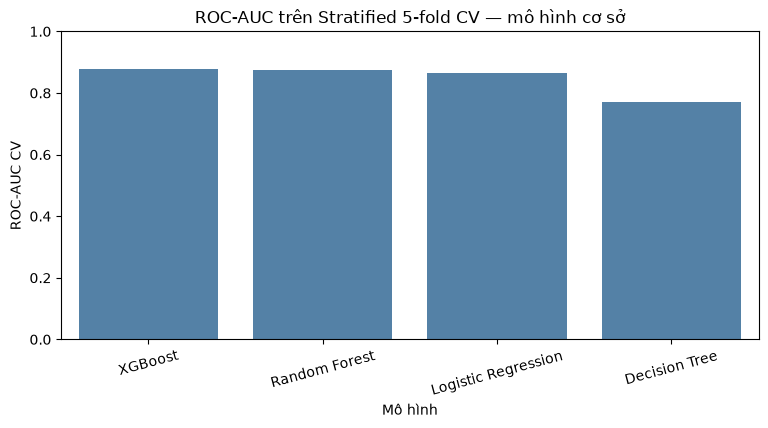

In [29]:
# So sánh 4 mô hình cơ sở trên cùng cách chia fold
ket_qua_co_so = []
for ten, mo_hinh in cac_mo_hinh.items():
    diem = cross_validate(
        mo_hinh, X_train, y_train, cv=kiem_dinh_cheo,
        scoring={"roc_auc": "roc_auc", "accuracy": "accuracy", "f1": "f1"},
        n_jobs=-1, error_score="raise"
    )
    ket_qua_co_so.append({
        "Mô hình": ten,
        "ROC-AUC CV": diem["test_roc_auc"].mean(),
        "Độ lệch chuẩn AUC": diem["test_roc_auc"].std(),
        "Accuracy CV": diem["test_accuracy"].mean(),
        "F1 CV": diem["test_f1"].mean()
    })
bang_co_so = pd.DataFrame(ket_qua_co_so).sort_values("ROC-AUC CV", ascending=False)
display(bang_co_so.round(3))
plt.figure(figsize=(9, 4))
sns.barplot(data=bang_co_so, x="Mô hình", y="ROC-AUC CV", color="steelblue")
plt.ylim(0, 1)
plt.title("ROC-AUC trên Stratified 5-fold CV — mô hình cơ sở")
plt.xticks(rotation=15)
plt.show()

### 17. Hyperparameter tuning bằng RandomizedSearchCV

**Cách làm:** Tối ưu ROC-AUC của cả bốn mô hình bằng 5-fold CV trên train. Tất cả tham số chọn bằng CV, không dùng điểm test. `n_iter` được giới hạn để notebook chạy tương đối nhanh trên Colab; có thể tăng nếu muốn thử nhiều cấu hình hơn.

In [30]:
# Các không gian tìm kiếm tương đối gọn cho dữ liệu Titanic
khong_gian_tham_so = {
    "Logistic Regression": {
        "mo_hinh__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
        "mo_hinh__class_weight": [None, "balanced"]
    },
    "Decision Tree": {
        "mo_hinh__max_depth": [2, 3, 4, 5, 6, 8, None],
        "mo_hinh__min_samples_leaf": [1, 2, 4, 8, 12],
        "mo_hinh__min_samples_split": [2, 5, 10, 20]
    },
    "Random Forest": {
        "mo_hinh__n_estimators": [100, 200, 300],
        "mo_hinh__max_depth": [3, 5, 7, None],
        "mo_hinh__min_samples_leaf": [1, 2, 4],
        "mo_hinh__max_features": ["sqrt", 0.8]
    },
    "XGBoost": {
        "mo_hinh__n_estimators": [100, 200, 300],
        "mo_hinh__max_depth": [2, 3, 4, 5],
        "mo_hinh__learning_rate": [0.02, 0.05, 0.1],
        "mo_hinh__subsample": [0.8, 1.0],
        "mo_hinh__colsample_bytree": [0.8, 1.0],
        "mo_hinh__reg_lambda": [1, 5, 10]
    }
}

so_lan_thu = {
    "Logistic Regression": 10,
    "Decision Tree": 12,
    "Random Forest": 12,
    "XGBoost": 12
}

# Có thể đổi thành 5–6 để chạy thử nhanh hơn, rồi tăng lên để báo cáo
mo_hinh_tot_nhat = {}
ket_qua_tuning = []
for ten, pipeline in cac_mo_hinh.items():
    print("Đang tuning:", ten)
    tim_kiem = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=khong_gian_tham_so[ten],
        n_iter=so_lan_thu[ten],
        scoring="roc_auc",
        cv=kiem_dinh_cheo,
        n_jobs=-1,
        random_state=42,
        refit=True,
        error_score="raise"
    )
    tim_kiem.fit(X_train, y_train)
    mo_hinh_tot_nhat[ten] = tim_kiem.best_estimator_
    ket_qua_tuning.append({
        "Mô hình": ten,
        "ROC-AUC CV sau tuning": tim_kiem.best_score_,
        "Tham số tốt nhất": str(tim_kiem.best_params_)
    })

bang_tuning = pd.DataFrame(ket_qua_tuning).sort_values("ROC-AUC CV sau tuning", ascending=False)
display(bang_tuning)
ten_tot_nhat = bang_tuning.iloc[0]["Mô hình"]
mo_hinh_chon = mo_hinh_tot_nhat[ten_tot_nhat]
print("Mô hình được CHỌN theo ROC-AUC CV:", ten_tot_nhat)

Đang tuning: Logistic Regression
Đang tuning: Decision Tree
Đang tuning: Random Forest
Đang tuning: XGBoost


,Mô hình,ROC-AUC CV sau tuning,Tham số tốt nhất
3,XGBoost,0.890712,"{'mo_hinh__subsample': 1.0, 'mo_hinh__reg_lamb..."
2,Random Forest,0.886611,"{'mo_hinh__n_estimators': 300, 'mo_hinh__min_s..."
0,Logistic Regression,0.866436,"{'mo_hinh__class_weight': None, 'mo_hinh__C': 10}"
1,Decision Tree,0.864687,"{'mo_hinh__min_samples_split': 20, 'mo_hinh__m..."


Mô hình được CHỌN theo ROC-AUC CV: XGBoost


### 18. Đánh giá cuối cùng trên tập validation 

**Cách làm:** Với mỗi mô hình đã tuning, tính Accuracy, Precision, Recall, F1, ROC-AUC trên cùng tập validation nội bộ. Bảng dùng để *mô tả*; không chọn lại mô hình dựa trên test. Confusion Matrix và ROC của mô hình được chọn theo CV được minh họa riêng.

,Mô hình,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.855,0.841,0.768,0.803,0.882
2,Random Forest,0.821,0.803,0.710,0.754,0.855
1,Decision Tree,0.816,0.750,0.783,0.766,0.845
3,XGBoost,0.821,0.803,0.710,0.754,0.839


Mô hình được chọn qua CV: XGBoost
                precision    recall  f1-score   support

Không sống sót       0.83      0.89      0.86       110
      Sống sót       0.80      0.71      0.75        69

      accuracy                           0.82       179
     macro avg       0.82      0.80      0.81       179
  weighted avg       0.82      0.82      0.82       179



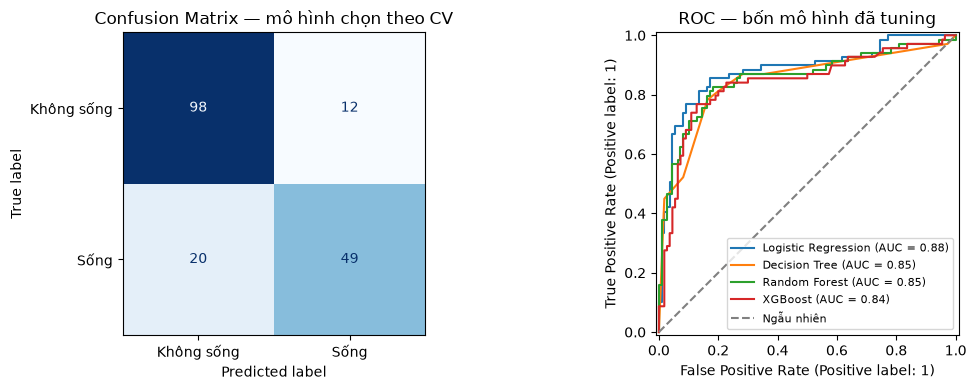

In [31]:
# Tập test được sử dụng ở đây lần đầu cho đánh giá mô hình
ket_qua_test = []
for ten, mo_hinh in mo_hinh_tot_nhat.items():
    du_doan = mo_hinh.predict(X_test)
    xac_suat = mo_hinh.predict_proba(X_test)[:, 1]
    ket_qua_test.append({
        "Mô hình": ten,
        "Accuracy": accuracy_score(y_test, du_doan),
        "Precision": precision_score(y_test, du_doan, zero_division=0),
        "Recall": recall_score(y_test, du_doan, zero_division=0),
        "F1": f1_score(y_test, du_doan, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, xac_suat)
    })
bang_test = pd.DataFrame(ket_qua_test).sort_values("ROC-AUC", ascending=False)
display(bang_test.round(3))

print("Mô hình được chọn qua CV:", ten_tot_nhat)
print(classification_report(y_test, mo_hinh_chon.predict(X_test), target_names=["Không sống sót", "Sống sót"]))
fig, truc = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_estimator(
    mo_hinh_chon, X_test, y_test, display_labels=["Không sống", "Sống"],
    cmap="Blues", ax=truc[0], colorbar=False
)
truc[0].set_title("Confusion Matrix — mô hình chọn theo CV")
for ten, mo_hinh in mo_hinh_tot_nhat.items():
    RocCurveDisplay.from_estimator(mo_hinh, X_test, y_test, ax=truc[1], name=ten)
truc[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Ngẫu nhiên")
truc[1].set_title("ROC — bốn mô hình đã tuning")
truc[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 19. Giải thích mô hình tốt nhất bằng Permutation Importance

**Cách làm:** Xáo trộn từng cột đầu vào trên **validation nội bộ** và đo mức giảm ROC-AUC. Chỉ số càng cao, đặc trưng càng hữu ích cho dự đoán của mô hình *trên tập này*. Đây không phải bằng chứng nhân quả. Phân tích trên validation nội bộ được dùng để giải thích, không để tuning lại.

,Đặc trưng,Giảm ROC-AUC trung bình,Độ lệch chuẩn
10,Danh_xung,0.1756,0.0417
6,Gia_ve_moi_nguoi,0.0331,0.0112
8,Pclass,0.0310,0.0087
7,Sex,0.0250,0.0134
0,Age,0.0227,0.0092
4,So_nguoi_than,0.0111,0.0055
9,Embarked,0.0075,0.0064
2,SibSp,0.0025,0.0016
3,Parch,0.0001,0.0010
5,Di_mot_minh_so,-0.0002,0.0003


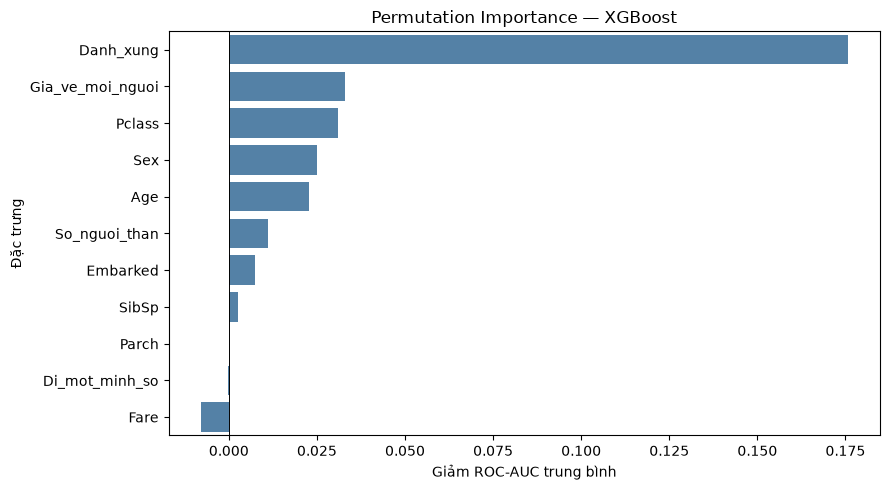

Lưu ý: đặc trưng tương quan mạnh có thể cùng chia sẻ tầm quan trọng.


In [32]:
# Tính tầm quan trọng ngay trên các cột gốc, không cần giải mã các cột One-Hot
ket_qua_hoan_vi = permutation_importance(
    mo_hinh_chon, X_test, y_test,
    n_repeats=10, random_state=42, scoring="roc_auc", n_jobs=-1
)
bang_quan_trong = pd.DataFrame({
    "Đặc trưng": X_test.columns,
    "Giảm ROC-AUC trung bình": ket_qua_hoan_vi.importances_mean,
    "Độ lệch chuẩn": ket_qua_hoan_vi.importances_std
}).sort_values("Giảm ROC-AUC trung bình", ascending=False)
display(bang_quan_trong.round(4))
plt.figure(figsize=(9, 5))
sns.barplot(data=bang_quan_trong, y="Đặc trưng", x="Giảm ROC-AUC trung bình", color="steelblue")
plt.axvline(0, color="black", linewidth=0.7)
plt.title("Permutation Importance — " + ten_tot_nhat)
plt.tight_layout()
plt.show()
print("Lưu ý: đặc trưng tương quan mạnh có thể cùng chia sẻ tầm quan trọng.")

### 20. Diễn giải bổ sung: Logistic Regression và cây quyết định

**Cách làm:** Logistic Regression cho hệ số theo những biến đã mã hóa/chuẩn hóa; dấu dương/âm thể hiện chiều liên hệ với log-odds sống sót khi giữ các đặc trưng khác cố định. Cây quyết định giúp minh họa quy tắc dự đoán. Hệ số **không phải** tác động nhân quả; đặc trưng phụ thuộc nhau có thể làm hệ số kém ổn định.

,Đặc trưng sau xử lý,Hệ số,Độ lớn tuyệt đối
16,phan_loai__Danh_xung_Master,2.388,2.388
7,phan_loai__Sex_female,1.706,1.706
8,phan_loai__Sex_male,-1.394,1.394
9,phan_loai__Pclass_1,1.166,1.166
17,phan_loai__Danh_xung_Miss,-0.933,0.933
11,phan_loai__Pclass_3,-0.912,0.912
18,phan_loai__Danh_xung_Mr,-0.649,0.649
13,phan_loai__Embarked_Q,0.432,0.432
2,so__SibSp,-0.381,0.381
0,so__Age,-0.360,0.360


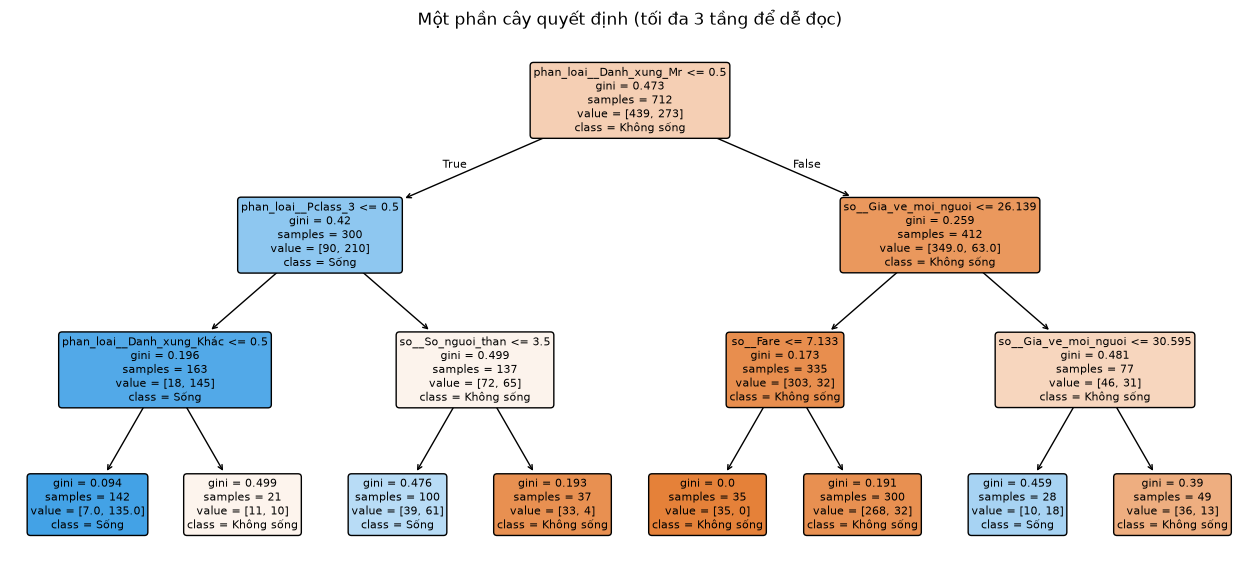

In [33]:
# Hệ số logistic đã tuning
mo_hinh_logistic = mo_hinh_tot_nhat["Logistic Regression"]
ten_cot_logistic = mo_hinh_logistic.named_steps["xu_ly"].get_feature_names_out()
he_so = mo_hinh_logistic.named_steps["mo_hinh"].coef_[0]
bang_he_so = pd.DataFrame({"Đặc trưng sau xử lý": ten_cot_logistic, "Hệ số": he_so})
bang_he_so["Độ lớn tuyệt đối"] = bang_he_so["Hệ số"].abs()
display(bang_he_so.sort_values("Độ lớn tuyệt đối", ascending=False).head(15).round(3))

# Trực quan cây Decision Tree: giới hạn độ sâu khi HIỂN THỊ, không thay mô hình đã huấn luyện
mo_hinh_cay = mo_hinh_tot_nhat["Decision Tree"]
ten_cot_cay = mo_hinh_cay.named_steps["xu_ly"].get_feature_names_out()
plt.figure(figsize=(16, 7))
plot_tree(
    mo_hinh_cay.named_steps["mo_hinh"],
    feature_names=ten_cot_cay,
    class_names=["Không sống", "Sống"],
    filled=True, rounded=True, max_depth=3, fontsize=8
)
plt.title("Một phần cây quyết định (tối đa 3 tầng để dễ đọc)")
plt.show()

### 21. Kiểm tra overfitting: so sánh train và validation nội bộ của mô hình đã chọn

**Cách làm:** So sánh ROC-AUC train và validation nội bộ. Chênh lệch lớn có thể là dấu hiệu overfitting, nhưng một lần chia train/validation trên mẫu nhỏ chưa đủ kết luận chắc chắn.

In [34]:
auc_train = roc_auc_score(y_train, mo_hinh_chon.predict_proba(X_train)[:, 1])
auc_test = roc_auc_score(y_test, mo_hinh_chon.predict_proba(X_test)[:, 1])
print(f"ROC-AUC train: {auc_train:.3f}")
print(f"ROC-AUC test : {auc_test:.3f}")
print(f"Chênh lệch  : {auc_train - auc_test:.3f}")
print("Mô hình được lựa chọn theo CV, không theo điểm test.")

ROC-AUC train: 0.982
ROC-AUC test : 0.839
Chênh lệch  : 0.143
Mô hình được lựa chọn theo CV, không theo điểm test.


### 22. Dự đoán trên `test.csv` chính thức của Kaggle và xuất `submission.csv`

**Cách làm:** Đọc trực tiếp `test.csv` từ thư mục `data` trên GitHub. Tập này có **418 hành khách** và **không có cột `Survived`**, vì vậy **không thể tính Accuracy, F1 hay ROC-AUC** trực tiếp. Ta tạo **đúng các đặc trưng** như tập train, huấn luyện lại cấu hình đã chọn theo cross-validation trên toàn bộ `train.csv`, rồi xuất file theo định dạng Kaggle: `PassengerId,Survived`.

**Phân biệt:** `X_test, y_test` ở các mục trước là tập *validation nội bộ* (có nhãn, tách từ `train.csv`); `du_lieu_kaggle_test` bên dưới là tập Kaggle chưa có nhãn. `gender_submission.csv` là **submission mẫu/baseline**, không phải đáp án thật.


In [ ]:
# Lấy test set
url_test_kaggle = "https://raw.githubusercontent.com/hnhun2306b5tneu-crypto/Titanic/main/data/test.csv"
du_lieu_kaggle_test = pd.read_csv(url_test_kaggle)

print("Kích thước Kaggle test:", du_lieu_kaggle_test.shape)
print("Có nhãn Survived?", "Survived" in du_lieu_kaggle_test.columns)
assert "Survived" not in du_lieu_kaggle_test.columns, "Kaggle test không nên có nhãn Survived."
assert du_lieu_kaggle_test["PassengerId"].is_unique, "PassengerId trong test phải duy nhất."

# Tạo đặc trưng giống hệt phần huấn luyện, không sử dụng thông tin nhãn
du_lieu_du_doan = du_lieu_kaggle_test.copy()
du_lieu_du_doan["Danh_xung"] = du_lieu_du_doan["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()
du_lieu_du_doan["Danh_xung"] = du_lieu_du_doan["Danh_xung"].where(
    du_lieu_du_doan["Danh_xung"].isin(["Mr", "Mrs", "Miss", "Master"]), "Khác"
)
du_lieu_du_doan["So_nguoi_than"] = du_lieu_du_doan["SibSp"] + du_lieu_du_doan["Parch"]
du_lieu_du_doan["Di_mot_minh_so"] = (du_lieu_du_doan["So_nguoi_than"] == 0).astype(int)
du_lieu_du_doan["Gia_ve_moi_nguoi"] = du_lieu_du_doan["Fare"] / (du_lieu_du_doan["So_nguoi_than"] + 1)

# Pipeline đã fit từ train tự động xử lý các giá trị Age/Fare/Embarked bị thiếu
X_kaggle_test = du_lieu_du_doan[cot_dau_vao].copy()
# Sau khi đánh giá validation, huấn luyện lại cấu hình đã chọn trên đủ 891 nhãn
# Không chọn lại tham số dựa trên Kaggle test; chỉ tận dụng thêm dữ liệu train
from sklearn.base import clone
mo_hinh_nop_kaggle = clone(mo_hinh_chon)
mo_hinh_nop_kaggle.fit(X, y)
du_doan_kaggle = mo_hinh_nop_kaggle.predict(X_kaggle_test).astype(int)

bang_nop_kaggle = pd.DataFrame({
    "PassengerId": du_lieu_kaggle_test["PassengerId"].astype(int),
    "Survived": du_doan_kaggle
})
assert bang_nop_kaggle.shape[0] == du_lieu_kaggle_test.shape[0]
assert list(bang_nop_kaggle.columns) == ["PassengerId", "Survived"]
assert set(bang_nop_kaggle["Survived"].unique()).issubset({0, 1})

# Lưu file để gửi lên Kaggle (không chứa nhãn thật)
bang_nop_kaggle.to_csv("submission.csv", index=False)
print("Đã tạo submission.csv với", len(bang_nop_kaggle), "dòng")
display(bang_nop_kaggle.head())
print("Số hành khách được dự đoán sống sót:", int(bang_nop_kaggle["Survived"].sum()))




Kích thước Kaggle test: (418, 11)
Có nhãn Survived? False
Đã tạo submission.csv với 418 dòng


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


Số hành khách được dự đoán sống sót: 153


## Giai đoạn 4 — Đánh giá tác động, hạn chế và khuyến nghị

### 4.1. Tổng hợp phát hiện từ phân tích mô tả

- **Tỷ lệ sống sót chung:** Khoảng **38,4%** hành khách trong tập huấn luyện sống sót.
- **Giới tính:** Nữ có tỷ lệ sống sót cao hơn nam; kiểm định Chi-square cho thấy mối liên hệ có ý nghĩa thống kê.
- **Hạng vé:** Hành khách hạng 1 có tỷ lệ sống sót cao hơn hạng 2 và hạng 3.
- **Tuổi, gia đình:** Trẻ em và nhóm đi cùng 1–2 người thân có tỷ lệ tương đối cao trong mẫu, nhưng có các nhóm nhỏ và thiếu tuổi.
- **Phân tích nâng cao:** Đối chiếu giá vé trong từng hạng, ba chiều tuổi × giới tính × hạng vé, danh xưng và cảng giúp nhìn nhận những khác biệt có thể bị che khuất trong bảng tổng hợp.

### 4.2. Khuyến nghị sử dụng kết quả

- Ưu tiên **phân tích theo nhiều nhóm kết hợp**, không suy luận từ một biến riêng lẻ.
- Khi đưa ra kết luận về nhóm ít người, báo cáo cả **cỡ mẫu và khoảng tin cậy**.
- Nếu dùng mô hình dự đoán, chọn qua **cross-validation**, đánh giá trên test độc lập và kiểm tra cả Recall, F1, ROC-AUC thay vì chỉ nhìn Accuracy.
- Với bối cảnh lịch sử, các kết quả chỉ mang tính **mô tả / dự đoán**, không chứng minh quy tắc cứu hộ hay mối quan hệ nhân quả.

### 4.3. Hạn chế

- `Age` thiếu 177/891 dòng; `Cabin` thiếu phần lớn thông tin. Những đặc trưng quan trọng như vị trí thực tế và quá trình sơ tán không có trong tập dữ liệu.
- Chỉ có **891 người** trong tập train có nhãn; đánh giá test 20% có dao động mẫu, còn tuning nhiều cấu hình cũng có nguy cơ chọn quá khớp CV.
- Các biến `Sex`, `Danh_xung`, `Pclass`, `So_nguoi_than` có quan hệ với nhau; feature importance và hệ số có thể biến động giữa các mô hình.
- XGBoost/Random Forest phức tạp hơn Logistic Regression; ROC-AUC tốt hơn một chút không mặc nhiên làm chúng phù hợp hơn cho mọi mục tiêu.

### 4.4. Hướng phát triển

1. Thử **Repeated Stratified K-Fold**, so sánh phân bố điểm thay vì dựa vào một split.
2. Thử **calibration** xác suất và lựa chọn ngưỡng theo chi phí sai lầm khi có bài toán ứng dụng rõ ràng.
3. Thực hiện **SHAP** cho mô hình cây khi cần phân tích ở cấp từng hành khách (cần kiểm tra tính ổn định và diễn giải không nhân quả).
4. Nếu có thông tin lịch sử độc lập đáng tin cậy, đánh giá liệu các biến mới thực sự cải thiện dự đoán ngoài mẫu hay không.
